In [2]:
import pandas as pd

file_path = dataset_path = "C:\\Users\\LENOVO\\OneDrive\\Desktop\\PROJECT\\rainfalll.CSV"
df = pd.read_csv(file_path)

# quick checks
print("shape:", df.shape)
print("year min/max:", df['YEAR'].min(), df['YEAR'].max())
print("unique subdivisions:", df['SUBDIVISION'].nunique())
print("duplicate SUBDIVISION-YEAR pairs:", df.duplicated(subset=['SUBDIVISION','YEAR']).sum())
print("\nmissing per column:\n", df.isna().sum().sort_values(ascending=False))
display(df.head())


shape: (4188, 19)
year min/max: 1901 2017
unique subdivisions: 36
duplicate SUBDIVISION-YEAR pairs: 0

missing per column:
 ANNUAL         26
OND            13
NOV            11
JJAS           10
DEC            10
MAM             9
JUL             7
OCT             7
MAR             6
JF              6
SEP             6
JUN             5
AUG             4
JAN             4
APR             4
FEB             3
MAY             3
YEAR            0
SUBDIVISION     0
dtype: int64


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


In [3]:
# Check missing values per column again
df.isna().sum().sort_values(ascending=False)

# See rows that have any missing values
missing_rows = df[df.isna().any(axis=1)]
display(missing_rows.head())


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
21,Andaman & Nicobar Islands,1923,79.5,0.0,NaN,91.3,293.5,808.4,636.9,182.2,560.5,131.9,197.4,70.6,NaN,79.5,NaN,2188.0,399.9
22,Andaman & Nicobar Islands,1924,28.7,0.0,14.8,89.7,191.2,261.2,493.3,290.9,251.2,331.1,378.6,NaN,NaN,28.7,295.7,1296.6,NaN
30,Andaman & Nicobar Islands,1932,2.8,2.5,10.1,58.2,479.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.3,548.0,NaN,NaN
34,Andaman & Nicobar Islands,1936,16.5,15.3,116.5,NaN,194.3,498.3,664.8,562.9,383.8,174.9,199.2,212.2,NaN,31.8,NaN,2109.8,586.3
40,Andaman & Nicobar Islands,1942,39.2,7.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.6,NaN,NaN,NaN



The code identifies rows with missing values in the dataset for the **Andaman & Nicobar Islands** subdivision from 1923 to 1942. It highlights missing data primarily in monthly (Jan-Dec) and quarterly columns. For example, data for certain months and quarters are missing in years like 1923, 1932, and 1942, indicating gaps that may need to be addressed.


In [4]:
# Fill monthly missing values using mean per subdivision
month_cols = ['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']

for col in month_cols:
    df[col] = df.groupby('SUBDIVISION')[col].transform(lambda x: x.fillna(x.mean()))

# Recalculate seasonal and annual totals to keep them consistent
df['JF'] = df['JAN'] + df['FEB']
df['MAM'] = df['MAR'] + df['APR'] + df['MAY']
df['JJAS'] = df['JUN'] + df['JUL'] + df['AUG'] + df['SEP']
df['OND'] = df['OCT'] + df['NOV'] + df['DEC']
df['ANNUAL'] = df['JF'] + df['MAM'] + df['JJAS'] + df['OND']


In [5]:
import numpy as np

# Calculate Z-scores for all monthly columns
z_scores = np.abs((df[month_cols] - df[month_cols].mean()) / df[month_cols].std())

# Flag rows with any extreme z-scores (>3)
outliers = df[(z_scores > 3).any(axis=1)]
print("Rows with extreme outliers:", len(outliers))
display(outliers.head())


Rows with extreme outliers: 741


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


Z-scores were calculated for all monthly rainfall columns to detect extreme outliers (|z| > 3).  
A total of **741 rows** were flagged as containing at least one extreme outlier.  
The displayed sample shows unusually high or low monthly rainfall values across multiple years for the Andaman & Nicobar Islands subdivision.


In [6]:
for col in month_cols:
    upper_limit = df[col].quantile(0.99)
    df[col] = np.where(df[col] > upper_limit, upper_limit, df[col])


In [7]:
# Convert wide format (months as columns) to long format
df_long = df.melt(
    id_vars=['SUBDIVISION', 'YEAR'],
    value_vars=month_cols,
    var_name='MONTH',
    value_name='RAINFALL_MM'
)

display(df_long.head())


,SUBDIVISION,YEAR,MONTH,RAINFALL_MM
0,Andaman & Nicobar Islands,1901,JAN,49.2
1,Andaman & Nicobar Islands,1902,JAN,0.0
2,Andaman & Nicobar Islands,1903,JAN,12.7
3,Andaman & Nicobar Islands,1904,JAN,9.4
4,Andaman & Nicobar Islands,1905,JAN,1.3


In [8]:
# Summary statistics for numeric columns
summary_stats = df.describe().T
display(summary_stats)



,count,mean,std,min,25%,50%,75%,max
YEAR,4188.0,1959.220630,33.717097,1901.0,1930.000,1959.00,1988.000,2017.000
JAN,4188.0,18.337291,29.610693,0.0,0.600,6.00,22.100,157.769
FEB,4188.0,21.163351,33.286494,0.0,0.500,6.50,26.600,165.251
MAR,4188.0,26.935677,43.843234,0.0,1.000,7.90,31.400,227.404
APR,4188.0,42.357575,64.281432,0.0,3.000,15.50,49.800,325.016
MAY,4188.0,84.572526,117.039732,0.0,8.675,36.90,98.200,544.330
JUN,4188.0,229.106904,229.241880,0.4,70.875,139.00,306.025,1025.690
JUL,4188.0,345.349195,260.898023,0.0,175.900,284.90,418.425,1376.792
AUG,4188.0,288.112252,180.803846,0.0,155.975,258.50,377.700,978.373
SEP,4188.0,196.279547,130.673561,0.1,100.400,173.70,266.225,625.643


Descriptive statistics were generated for all numeric columns in the dataset.  
Key insights include:

- YEAR ranges from 1901 to 2017, with a mean around 1959.
- Monthly rainfall values show large variability, with many months having minimum values at 0 and high standard deviations, indicating significant    fluctuations over the years.
- Annual rainfall has a wide range (22.6 to 6331.1 mm), with a high standard deviation (~907 mm), reflecting strong year-to-year variation.
- Seasonal aggregates (JF, MAM, JJAS, OND) also show broad ranges and high variability, especially JJAS, which has the highest values among all seasonal columns.

These statistics help understand the distribution, spread, and magnitude of rainfall across months, seasons, and years.


In [9]:
month_cols = ['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']
season_cols = ['JF','MAM','JJAS','OND']

# Monthly averages across all regions and years
avg_monthly = df[month_cols].mean().sort_values(ascending=False)
print("Average Rainfall by Month (mm):\n", avg_monthly)

# Seasonal averages
avg_seasonal = df[season_cols].mean().sort_values(ascending=False)
print("\nAverage Rainfall by Season (mm):\n", avg_seasonal)


Average Rainfall by Month (mm):
 JUL    345.349195
AUG    288.112252
JUN    229.106904
SEP    196.279547
OCT     94.796772
MAY     84.572526
APR     42.357575
NOV     39.037488
MAR     26.935677
FEB     21.163351
JAN     18.337291
DEC     18.048608
dtype: float64

Average Rainfall by Season (mm):
 JJAS    1064.637794
MAM      156.317736
OND      154.338622
JF        40.555982
dtype: float64


In [10]:
# Average annual rainfall per region
avg_rainfall_by_region = df.groupby('SUBDIVISION')['ANNUAL'].mean().sort_values(ascending=False)
display(avg_rainfall_by_region.head(10))  # Top 10 wettest regions
display(avg_rainfall_by_region.tail(10))  # 10 driest regions


SUBDIVISION
Arunachal Pradesh                     3423.971438
Coastal Karnataka                     3395.279642
Konkan & Goa                          2987.523077
Andaman & Nicobar Islands             2929.009855
Kerala                                2914.256410
Sub Himalayan West Bengal & Sikkim    2750.538462
Assam & Meghalaya                     2579.133333
Naga Mani Mizo Tripura                2432.735897
Lakshadweep                           1596.317672
Gangetic West Bengal                  1490.619658
Name: ANNUAL, dtype: float64

SUBDIVISION
Madhya Maharashtra            881.420513
West Uttar Pradesh            823.897436
Matathwada                    791.731624
Rayalseema                    764.988034
North Interior Karnataka      717.187179
East Rajasthan                656.496581
Punjab                        591.441880
Haryana Delhi & Chandigarh    528.434188
Saurashtra & Kutch            496.380342
West Rajasthan                294.115385
Name: ANNUAL, dtype: float64

In [11]:
# Average annual rainfall per year (all regions combined)
annual_trend = df.groupby('YEAR')['ANNUAL'].mean()
display(annual_trend.head())

# Quick summary of change
print("\nAverage rainfall in early 1900s:", annual_trend.head(10).mean())
print("Average rainfall in recent 10 years:", annual_trend.tail(10).mean())


YEAR
1901    1284.208571
1902    1337.288571
1903    1404.633158
1904    1236.780000
1905    1186.168571
Name: ANNUAL, dtype: float64


Average rainfall in early 1900s: 1320.2309292153227
Average rainfall in recent 10 years: 1335.229212164751


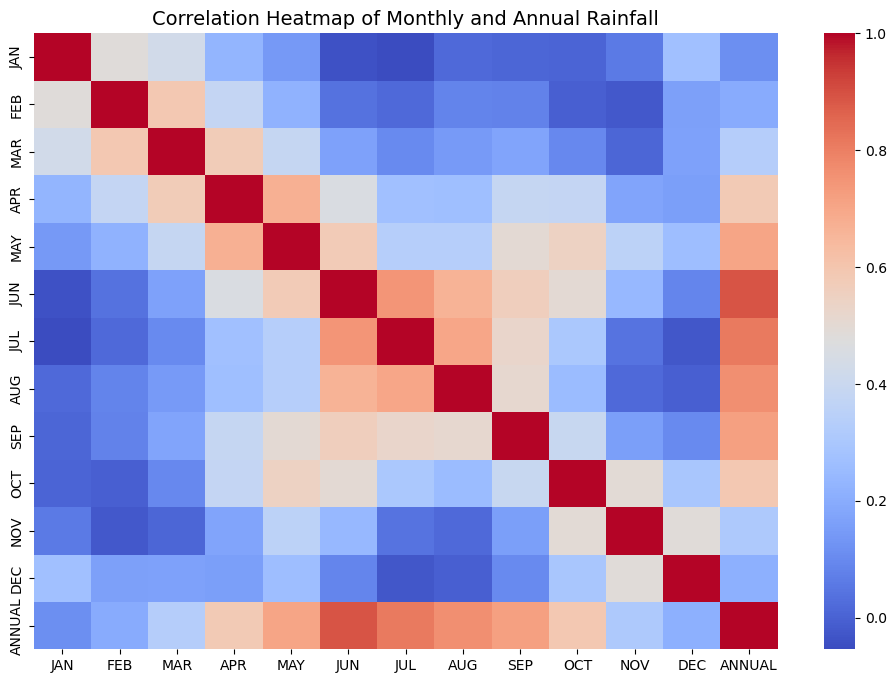

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
sns.heatmap(df[month_cols + ['ANNUAL']].corr(), annot=False, cmap='coolwarm')
plt.title("Correlation Heatmap of Monthly and Annual Rainfall", fontsize=14)
plt.show()


The heatmap shows how monthly rainfall correlates with each other and with annual rainfall.  
Strong positive correlations appear among the monsoon months (Jun–Sep), and these months also show the highest correlation with total annual rainfall. Winter and early-spring months (Jan–Mar) have weak or even negative correlations with the monsoon period and contribute less to annual totals.

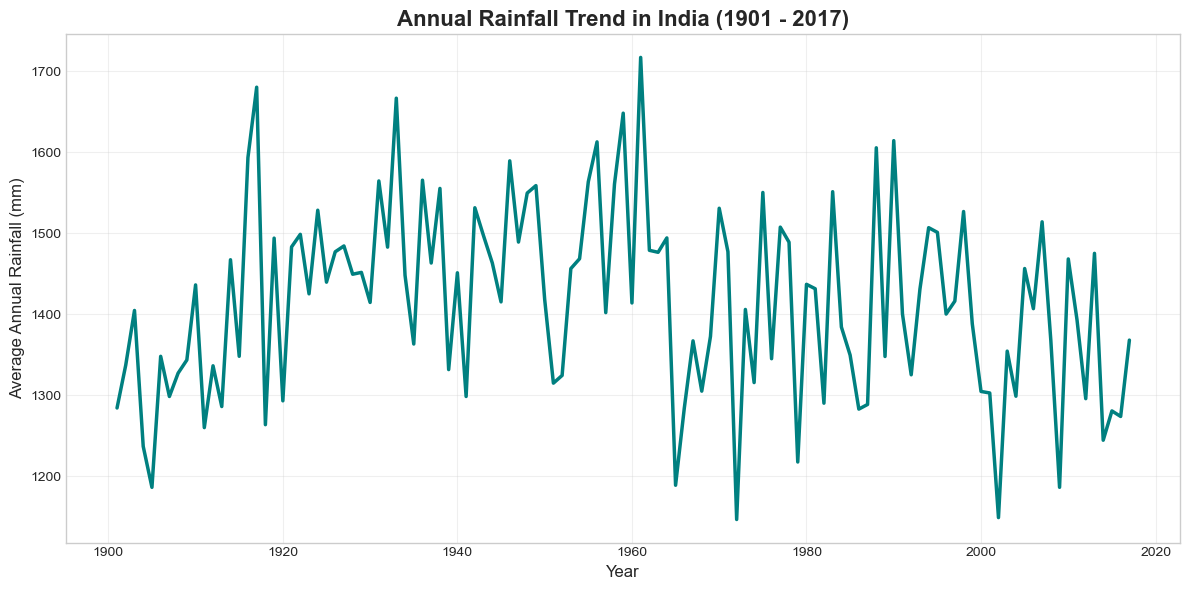

In [13]:
# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(12,6))

# Plot line chart for annual rainfall trend
sns.lineplot(x=annual_trend.index, y=annual_trend.values, color='teal', linewidth=2.5)

# Add title and labels
plt.title("Annual Rainfall Trend in India (1901 - 2017)", fontsize=16, weight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Annual Rainfall (mm)", fontsize=12)

# Add gridlines and smooth look
plt.grid(alpha=0.3)
plt.tight_layout()

# Show the plot
plt.show()


The plot above visualizes the annual rainfall trend in India from 1901 to 2017. It shows a fluctuating pattern of average annual rainfall (in mm), with noticeable peaks and troughs. The data is represented using a line chart, and gridlines have been added for clarity. The title and axis labels are appropriately set to enhance readability.

Fluctuating Rainfall Pattern: The average annual rainfall in India varies significantly over time, with periods of both higher and lower rainfall. This indicates that rainfall does not follow a steady increase or decrease but fluctuates year-to-year.

Rainfall Peaks and Troughs: There are noticeable peaks in some years (such as around 1920, 1940, and 1970) where the rainfall was higher than usual, and there are also troughs (such as in the 1960s and 1980s) where rainfall levels dropped significantly.

Decadal Variability: The graph highlights that rainfall trends exhibit cyclical patterns, possibly influenced by factors like monsoon behavior, climate changes, or global events such as El Niño or La Niña, which impact rainfall in the region.

Long-term Rainfall Fluctuations: Despite the fluctuations, the graph shows a general return to similar levels of rainfall in later years, suggesting that rainfall levels over the long term have remained relatively stable.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2876\4196070855.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=decade_trend, x='DECADE', y='ANNUAL', palette='Blues_d')


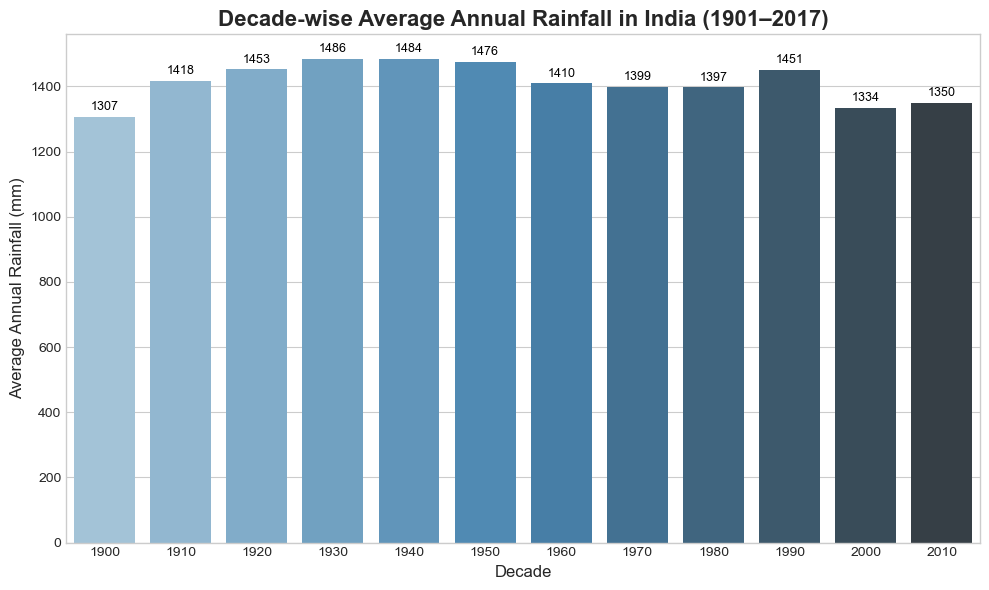

In [14]:
# Create a new column for decade
df['DECADE'] = (df['YEAR'] // 10) * 10

# Group by decade and calculate average rainfall
decade_trend = df.groupby('DECADE')['ANNUAL'].mean().reset_index()

# Plot decade-wise average rainfall
plt.figure(figsize=(10,6))
sns.barplot(data=decade_trend, x='DECADE', y='ANNUAL', palette='Blues_d')

# Add titles and labels
plt.title('Decade-wise Average Annual Rainfall in India (1901–2017)', fontsize=16, weight='bold')
plt.xlabel('Decade', fontsize=12)
plt.ylabel('Average Annual Rainfall (mm)', fontsize=12)

# Annotate each bar with rainfall value
for index, row in decade_trend.iterrows():
    plt.text(row.name, row['ANNUAL'] + 20, f"{row['ANNUAL']:.0f}", ha='center', fontsize=9, color='black')

plt.tight_layout()
plt.show()


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2876\2788965035.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_rainfall_by_region.head(10), x='ANNUAL', y='SUBDIVISION', palette='Blues_r')
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2876\2788965035.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_rainfall_by_region.tail(10), x='ANNUAL', y='SUBDIVISION', palette='Oranges')


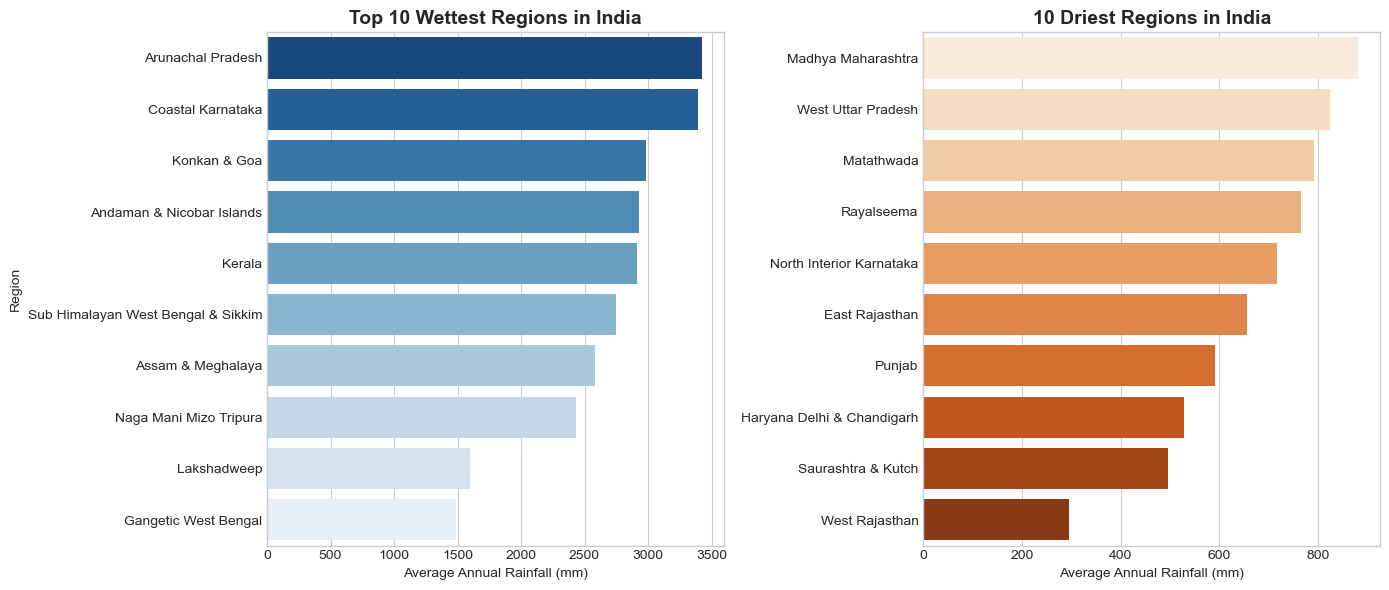

In [15]:
# Step 1: Calculate average rainfall by region
avg_rainfall_by_region = df.groupby('SUBDIVISION')['ANNUAL'].mean().sort_values(ascending=False).reset_index()

# Step 2: Plot top 10 wettest and driest regions side-by-side

plt.figure(figsize=(14,6))

# Top 10 wettest regions
plt.subplot(1, 2, 1)
sns.barplot(data=avg_rainfall_by_region.head(10), x='ANNUAL', y='SUBDIVISION', palette='Blues_r')
plt.title('Top 10 Wettest Regions in India', fontsize=14, weight='bold')
plt.xlabel('Average Annual Rainfall (mm)')
plt.ylabel('Region')

# 10 driest regions
plt.subplot(1, 2, 2)
sns.barplot(data=avg_rainfall_by_region.tail(10), x='ANNUAL', y='SUBDIVISION', palette='Oranges')
plt.title('10 Driest Regions in India', fontsize=14, weight='bold')
plt.xlabel('Average Annual Rainfall (mm)')
plt.ylabel('')

plt.tight_layout()
plt.show()





- Wettest Regions: Arunachal Pradesh, Coastal Karnataka, Konkan & Goa, Andaman & Nicobar Islands, and Kerala receive the highest annual rainfall (around 2900–3400 mm).

- Driest Regions: West Rajasthan, Saurashtra & Kutch, Haryana–Delhi–Chandigarh, Punjab, and East Rajasthan receive the least rainfall (around 500–900 mm).


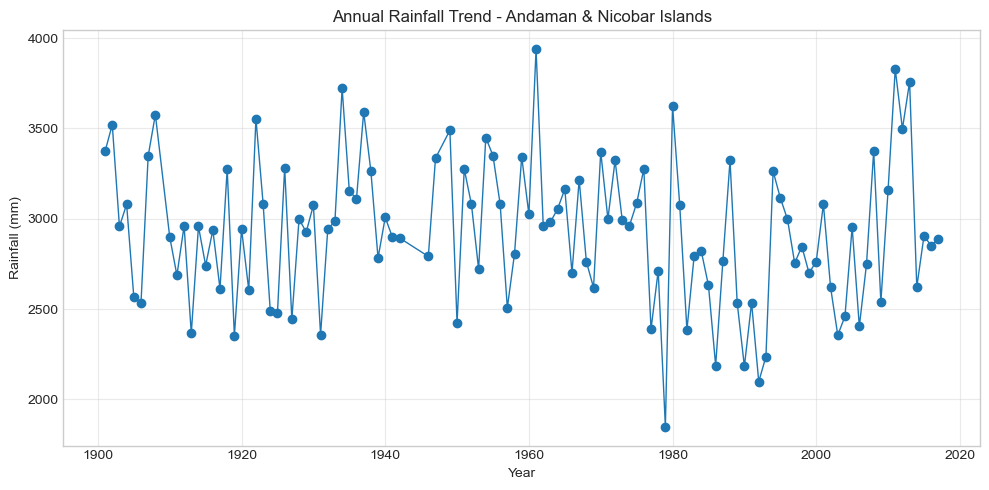

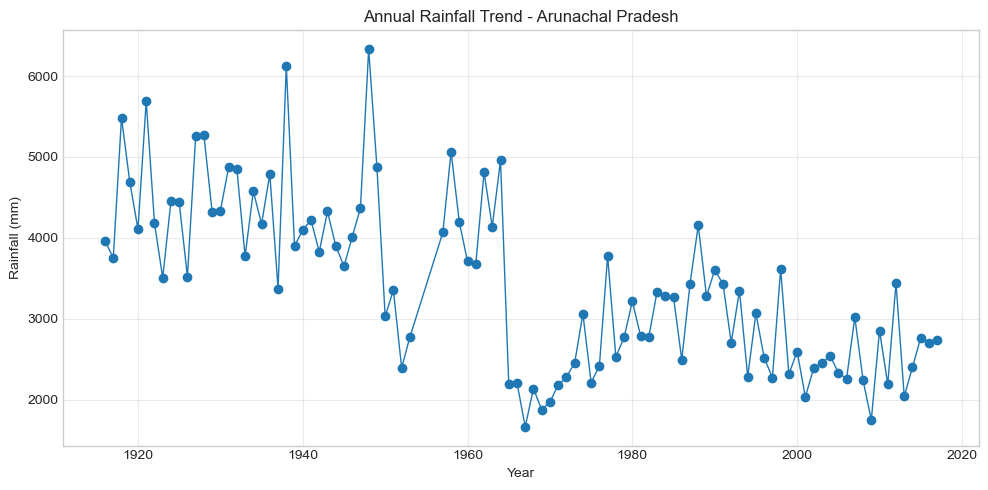

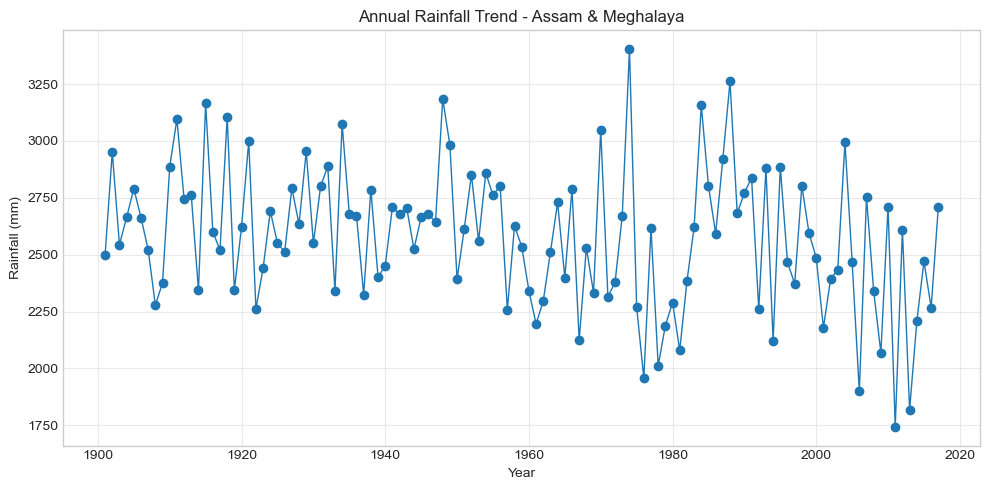

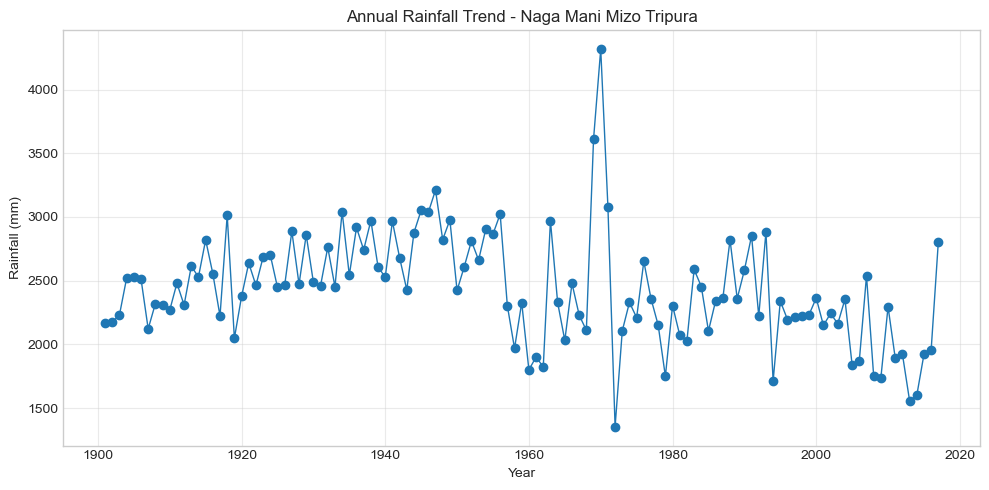

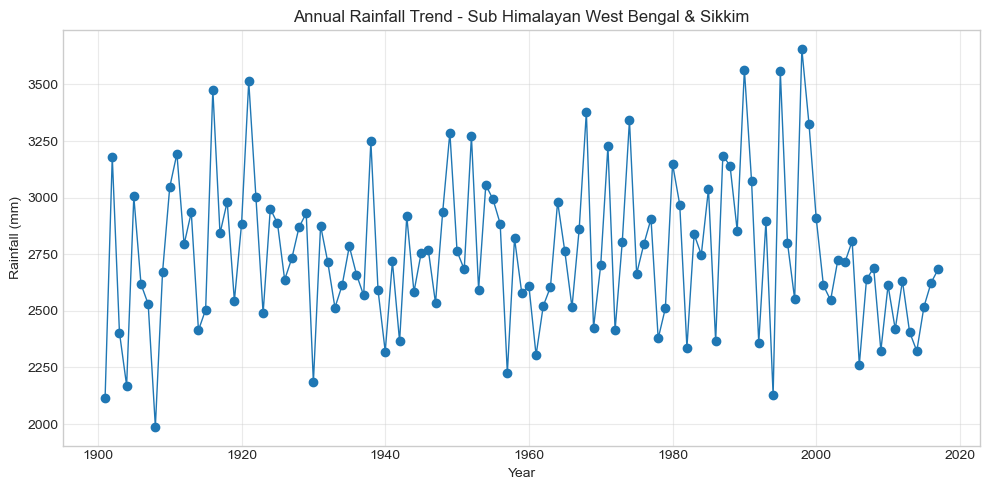

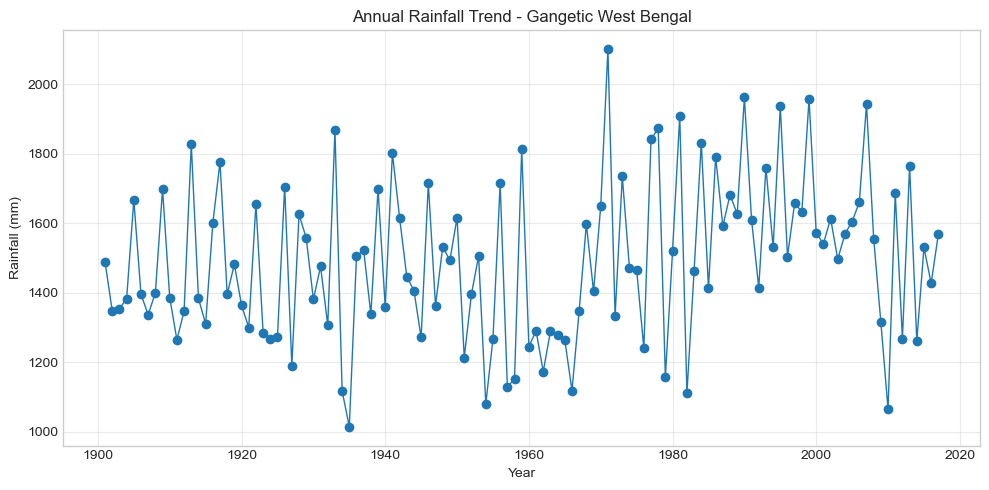

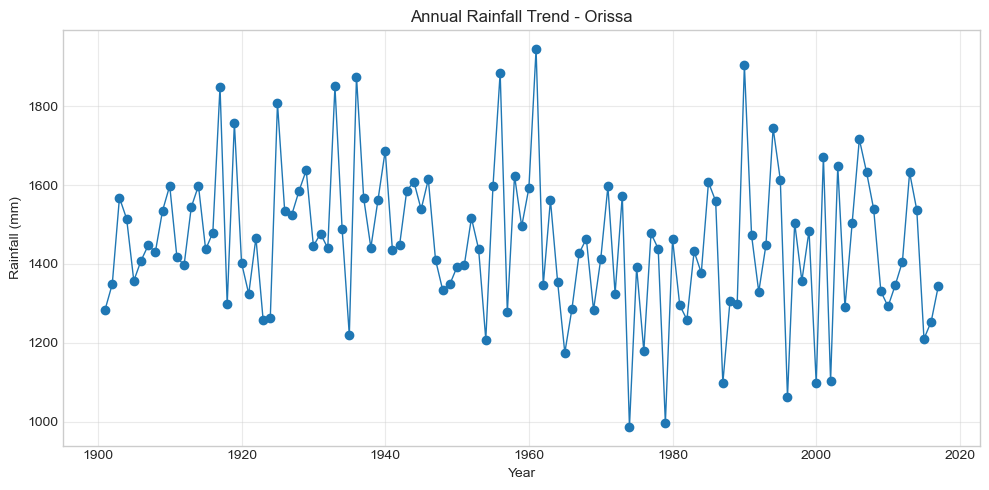

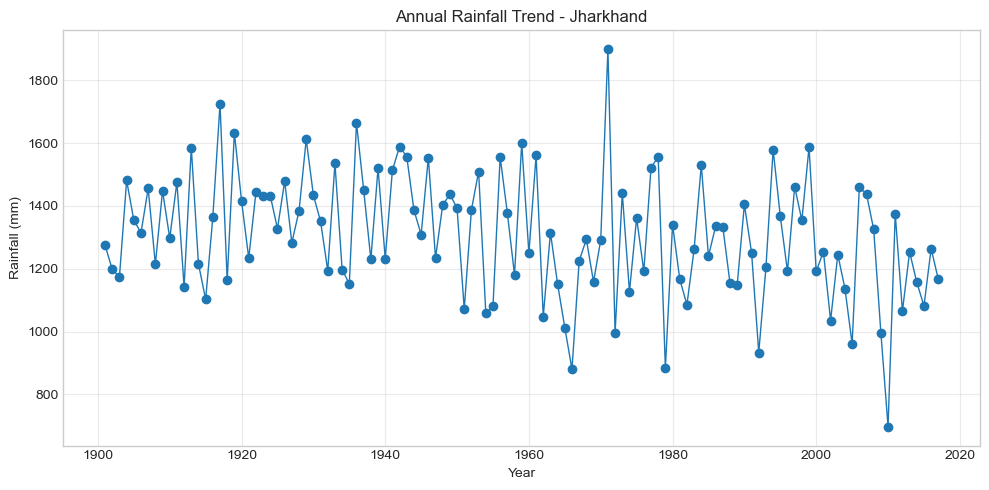

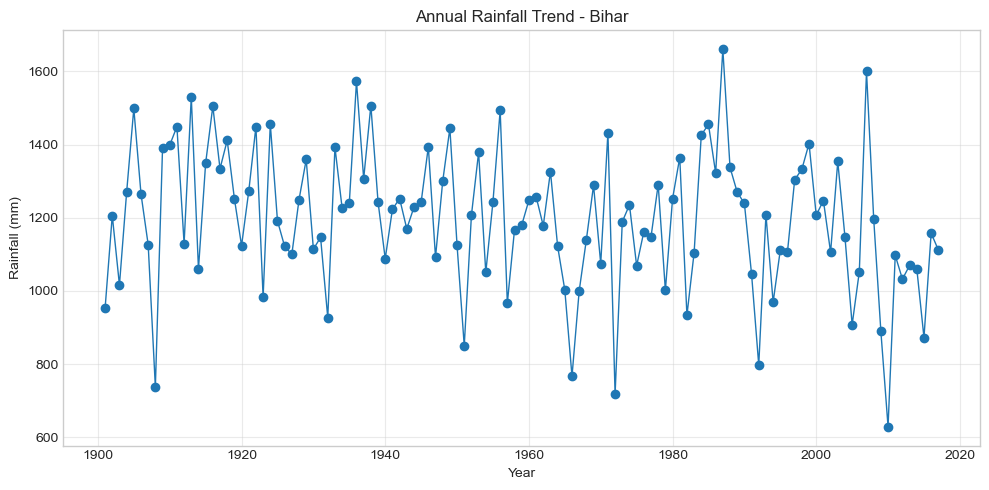

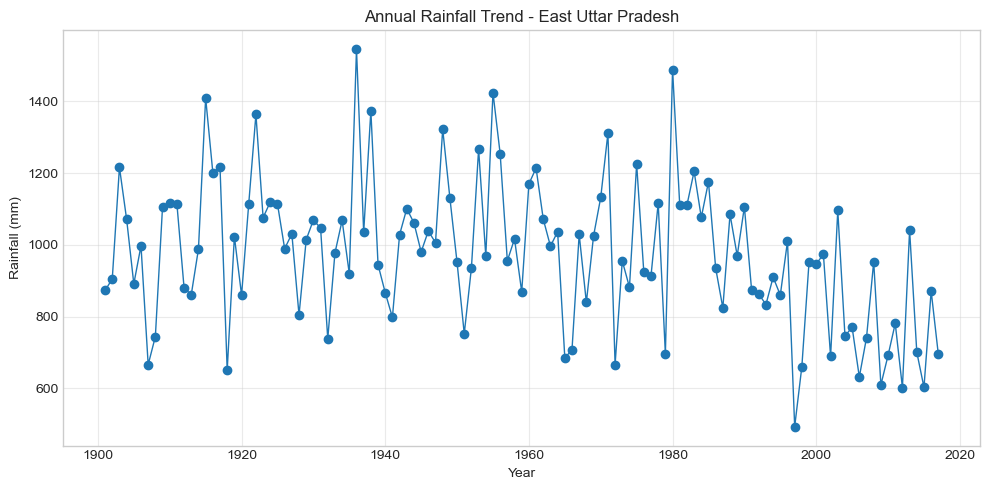

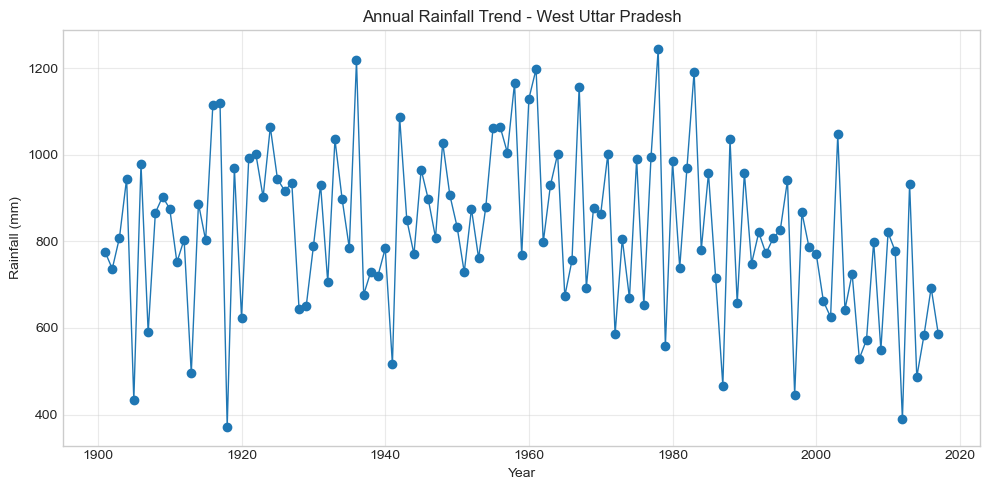

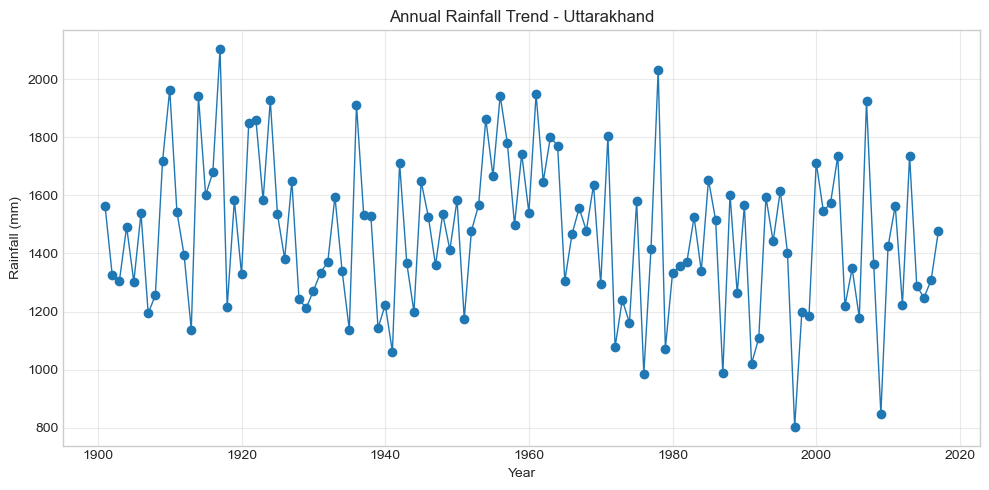

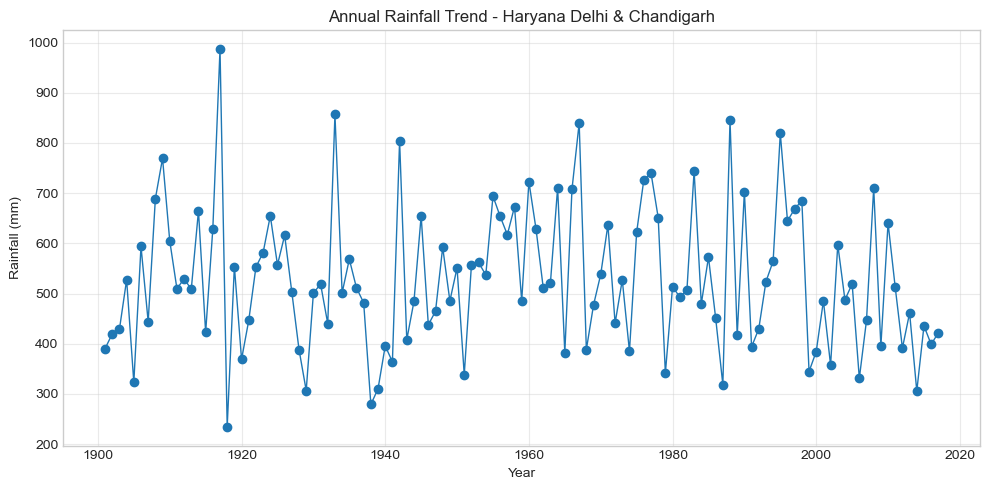

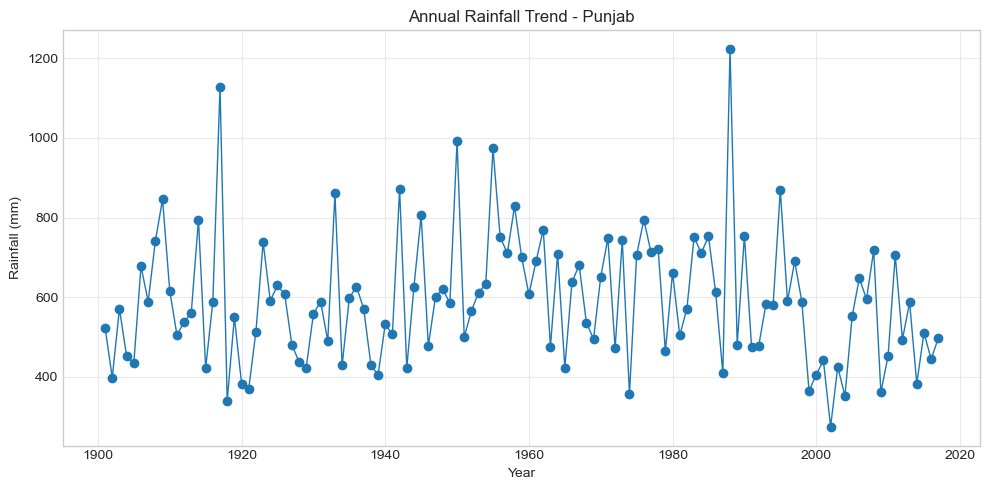

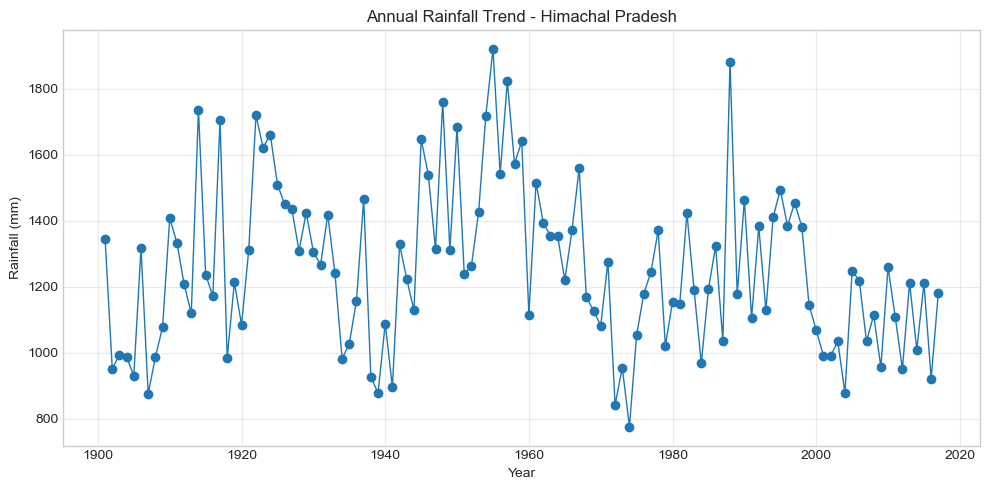

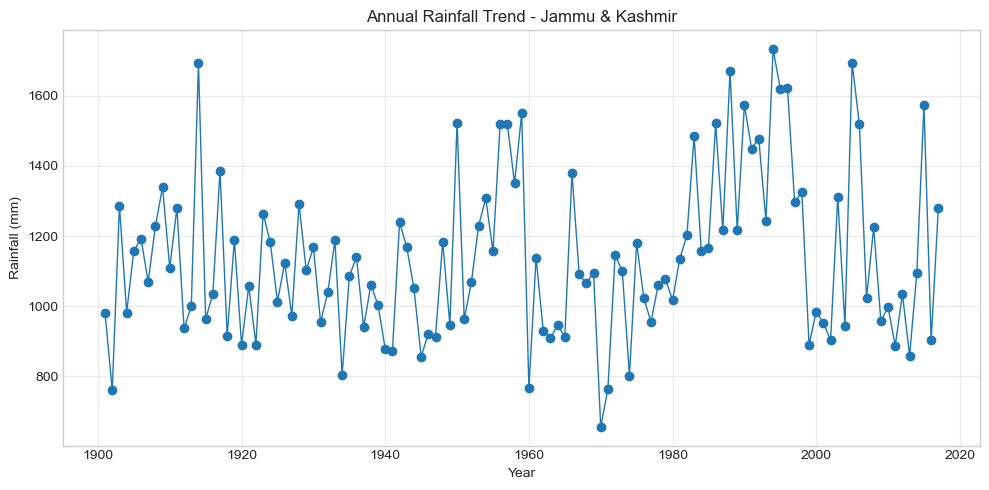

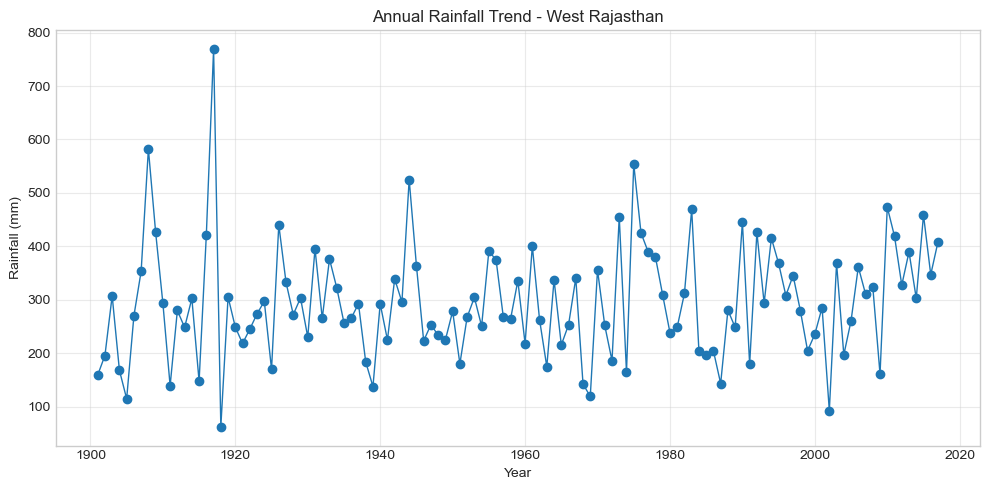

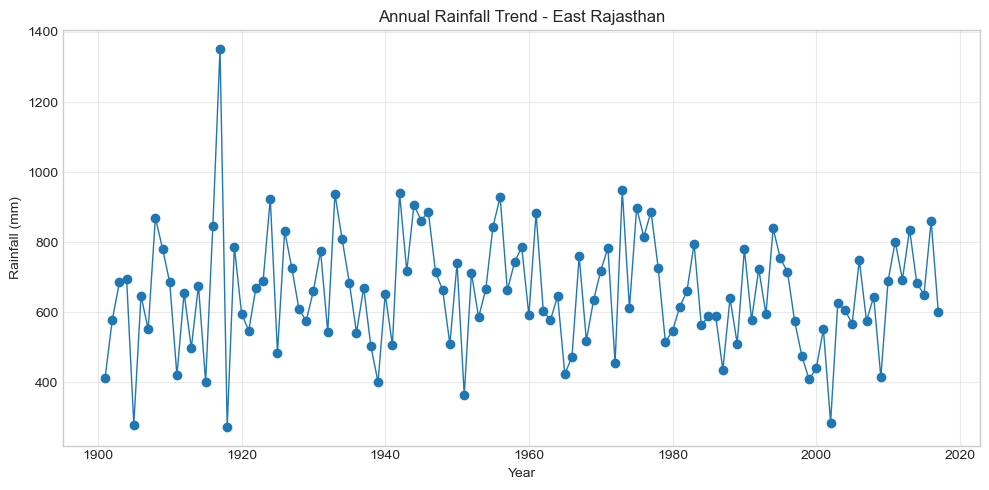

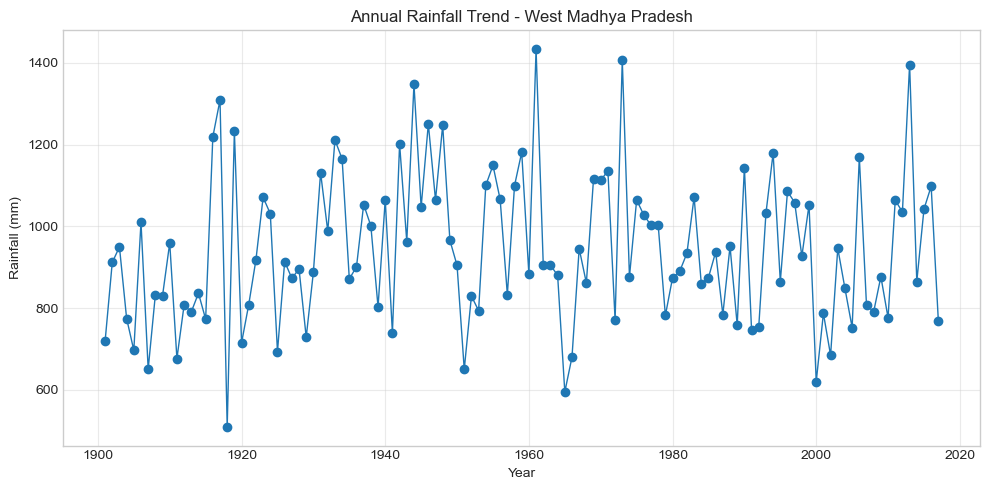

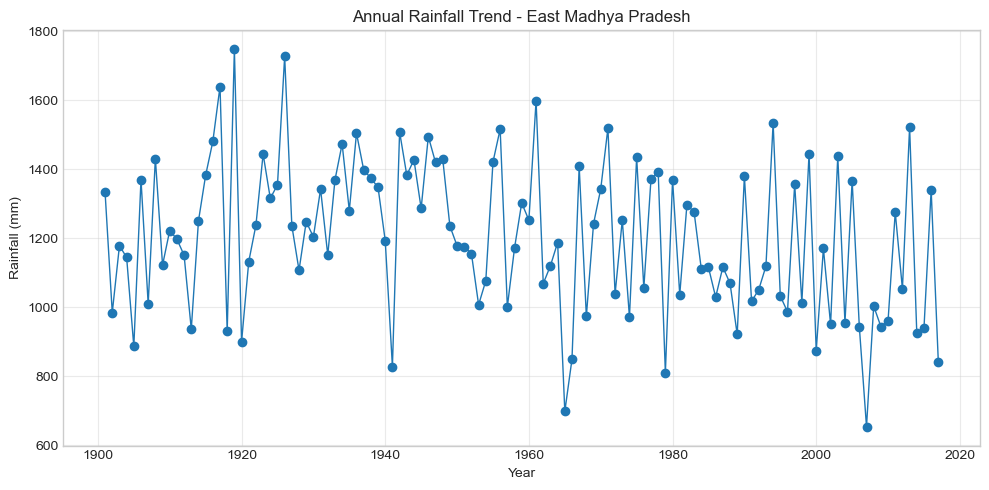

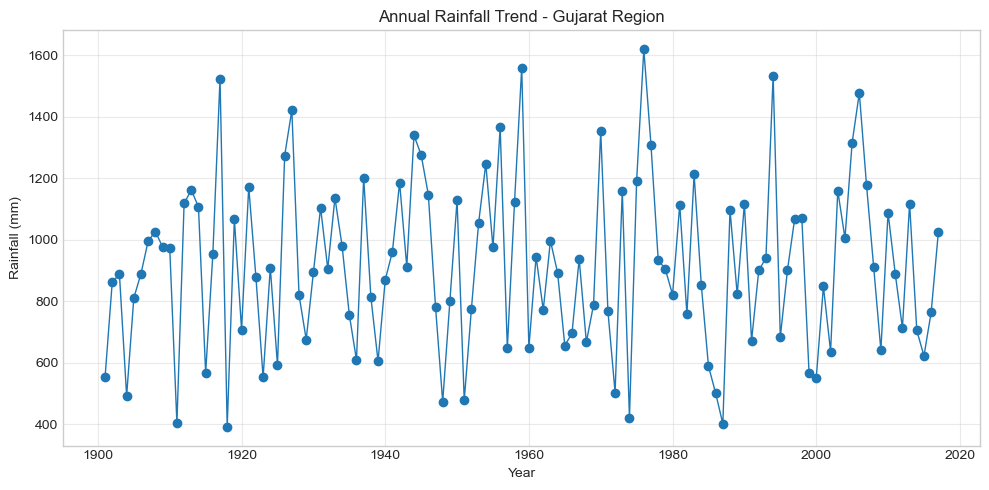

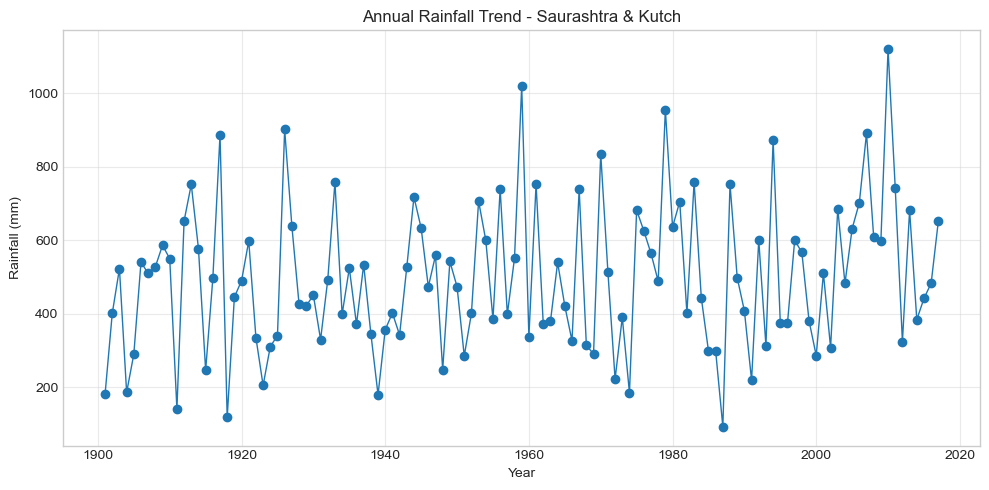

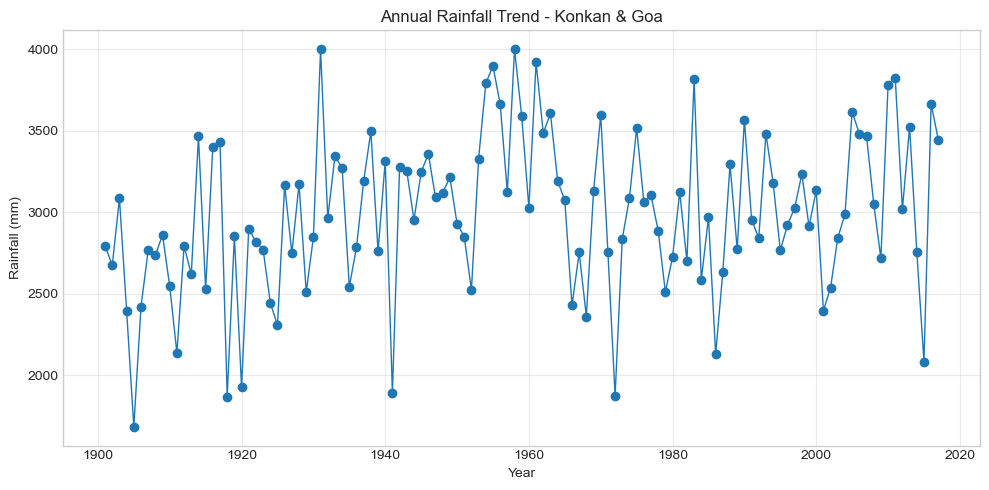

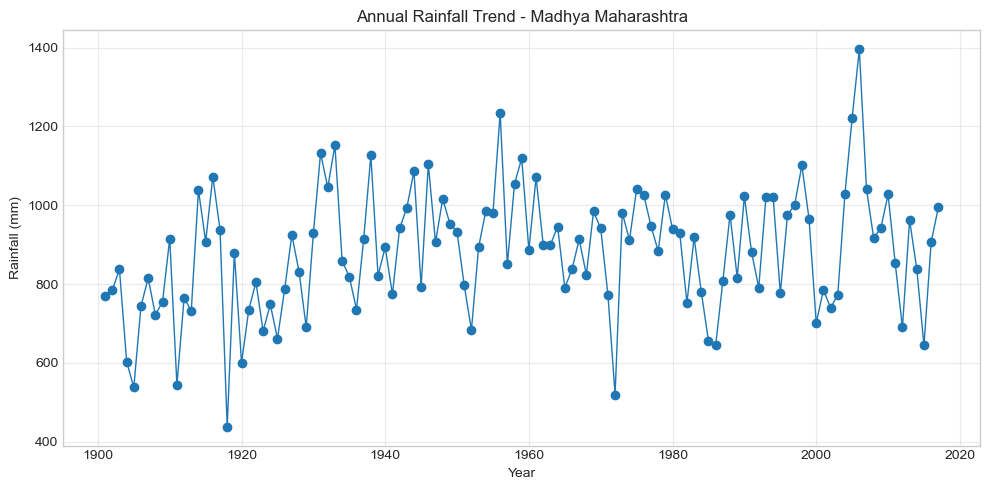

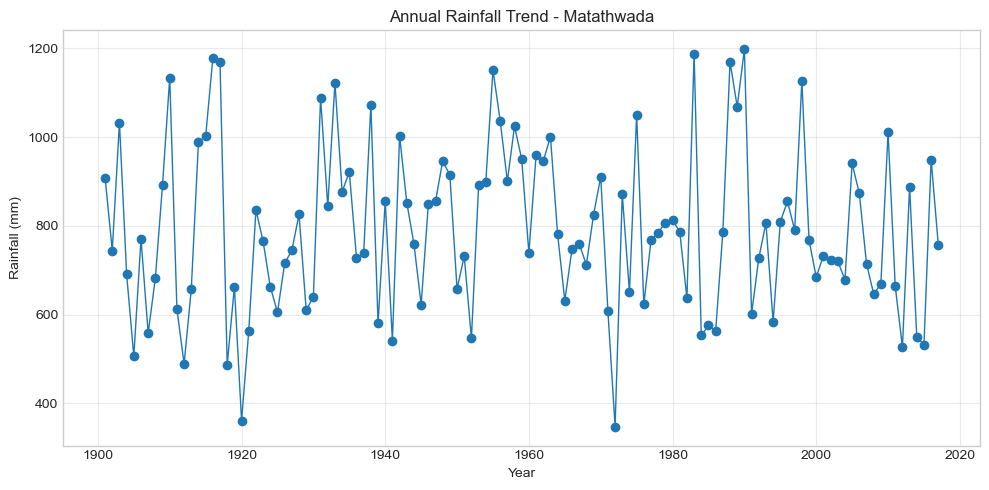

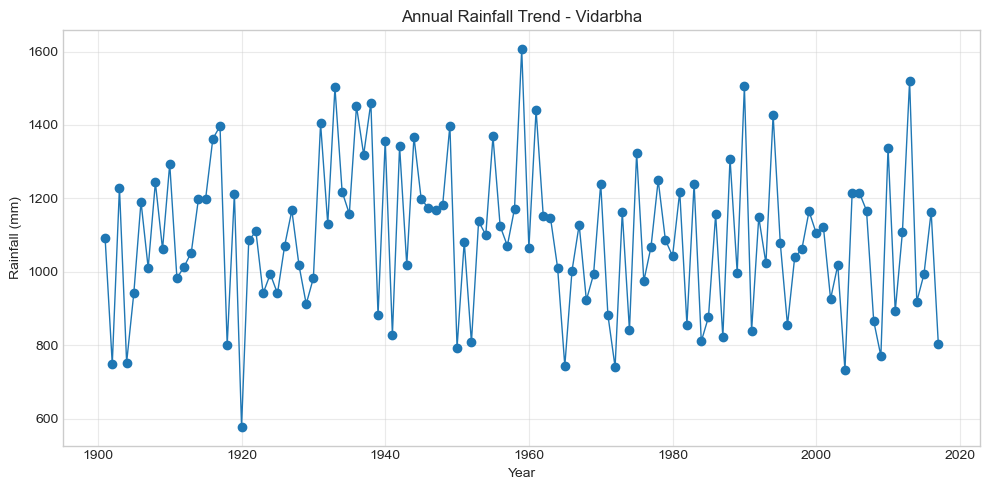

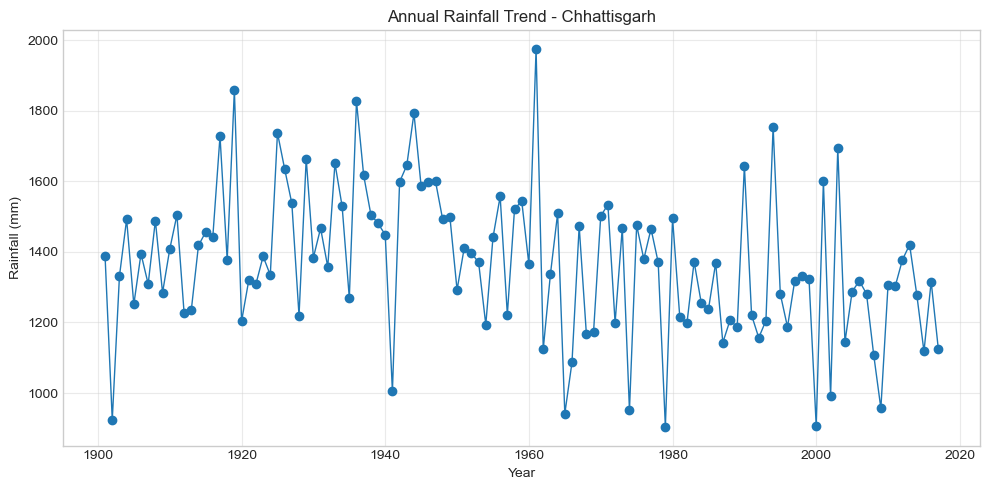

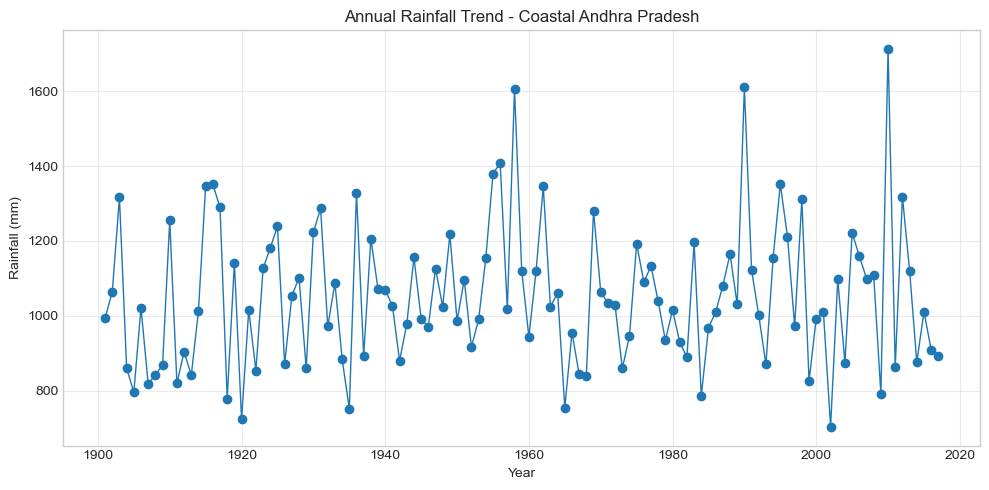

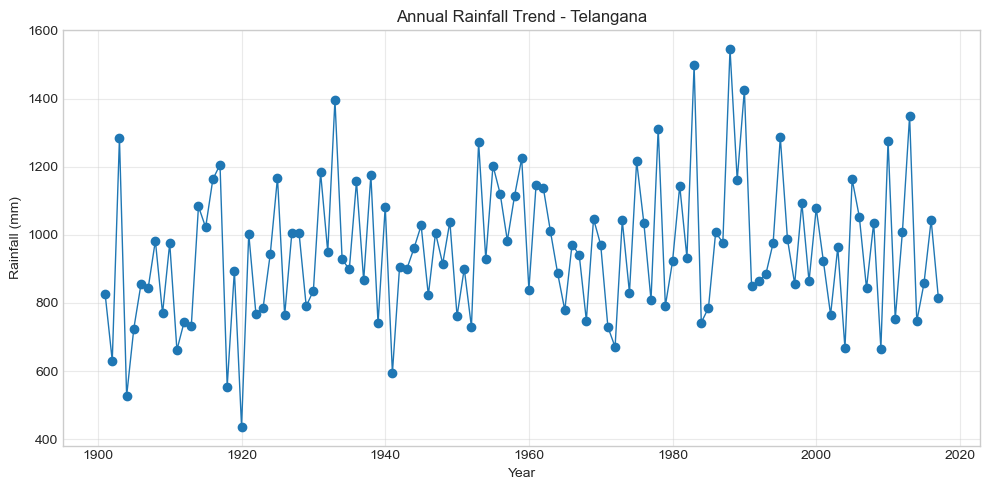

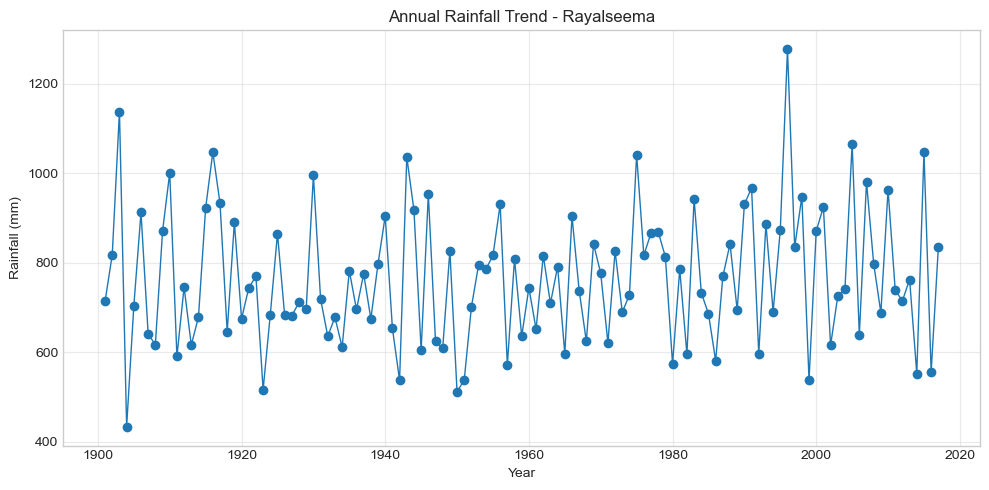

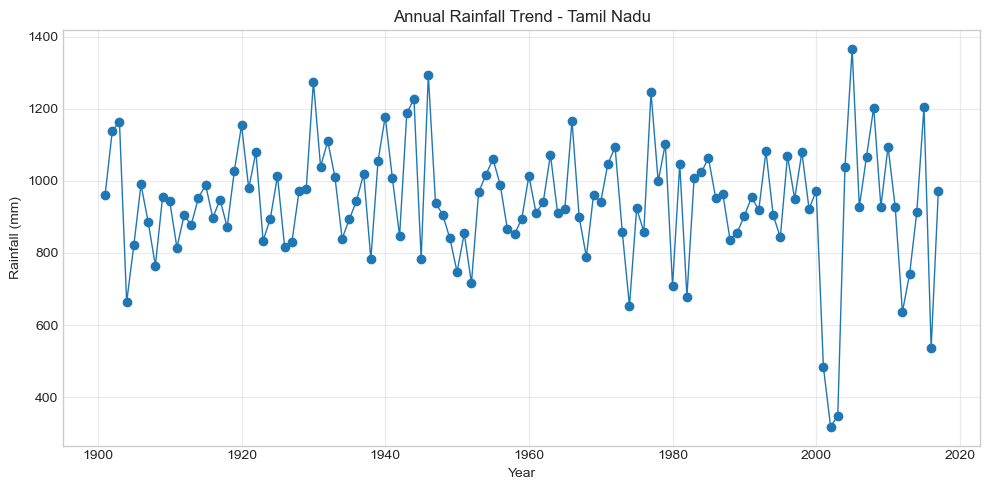

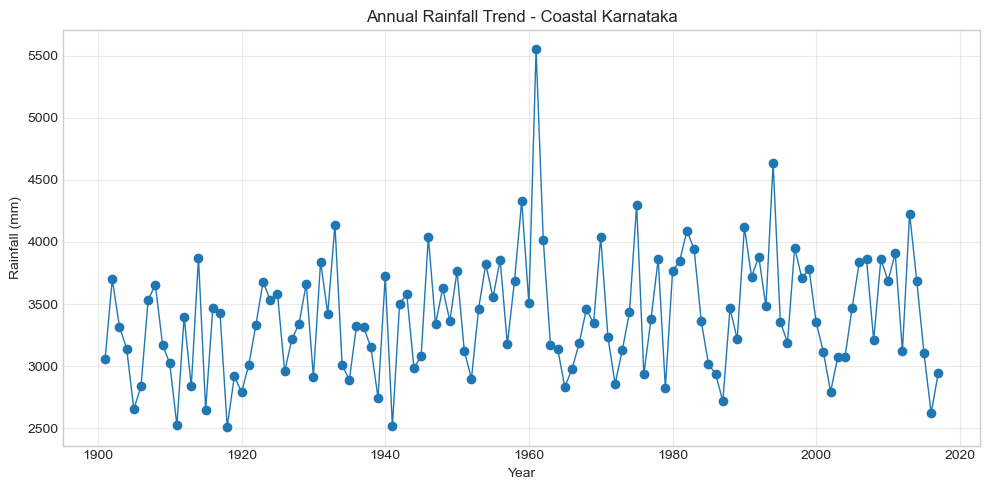

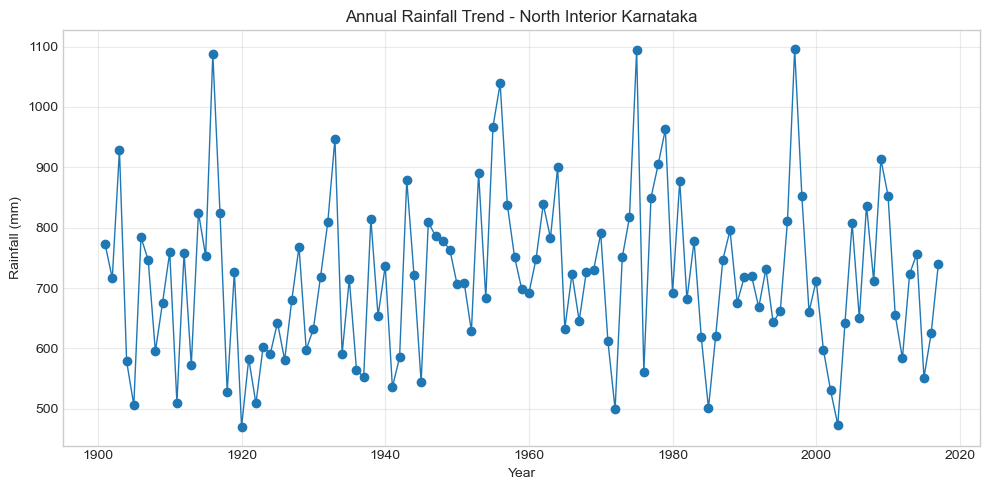

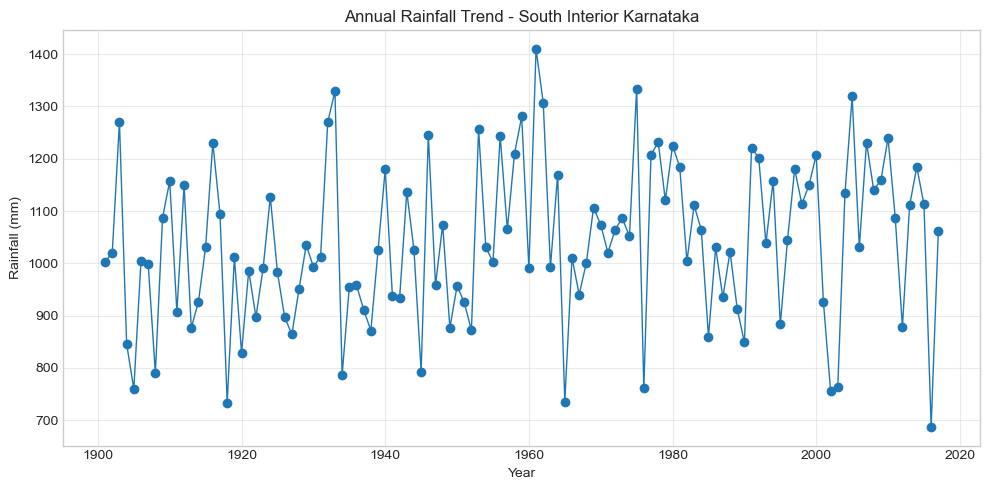

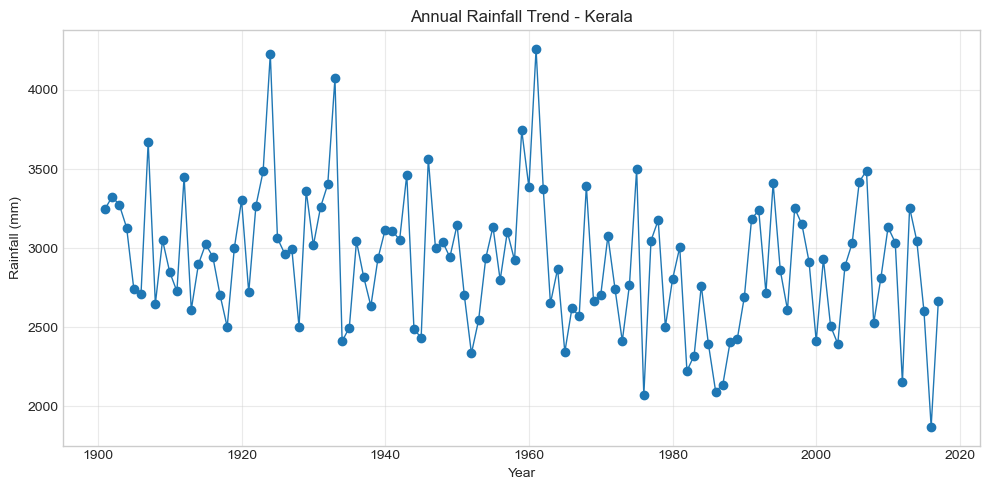

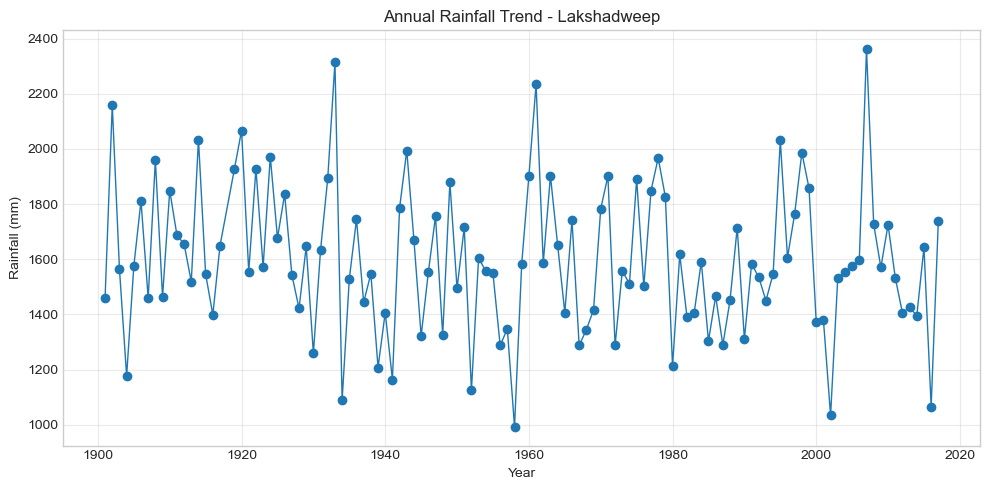

In [16]:
import matplotlib.pyplot as plt

# Loop through each subdivision/state and display the chart
for state in df["SUBDIVISION"].unique():
    state_df = df[df["SUBDIVISION"] == state]

    plt.figure(figsize=(10, 5))
    plt.plot(state_df["YEAR"], state_df["ANNUAL"], marker='o', linewidth=1)
    plt.title(f"Annual Rainfall Trend - {state}", fontsize=12)
    plt.xlabel("Year")
    plt.ylabel("Rainfall (mm)")
    plt.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.show()   # <-- This displays the chart in the output


In [18]:
data = {
    "Region / State": [
        "Andaman & Nicobar Islands", "Arunachal Pradesh", "Assam & Meghalaya", "Nagaland–Manipur–Mizoram–Tripura",
        "Sub-Himalayan West Bengal & Sikkim", "Gangetic West Bengal", "Odisha", "Jharkhand", "Bihar",
        "East Uttar Pradesh", "West Uttar Pradesh", "Uttarakhand", "Haryana–Delhi–Chandigarh", "Punjab",
        "Himachal Pradesh", "Jammu & Kashmir", "West Rajasthan", "East Rajasthan", "West Madhya Pradesh",
        "East Madhya Pradesh", "Gujarat Region", "Saurashtra & Kutch", "Konkan & Goa", "Madhya Maharashtra",
        "Marathwada", "Vidarbha", "Chhattisgarh", "Coastal Andhra Pradesh", "Telangana", "Rayalaseema",
        "Tamil Nadu", "Coastal Karnataka", "North Interior Karnataka", "South Interior Karnataka",
        "Kerala", "Lakshadweep"
    ],
    "Rainfall Range (mm)": [
        "2500–4500", "2000–5500", "1500–3500", "1200–2500", "2000–4000", "1200–2000", "1000–1800",
        "900–1600", "800–1500", "700–1300", "600–1200", "900–1600", "400–1000", "350–900",
        "900–1800", "600–1300", "100–500", "300–900", "700–1300", "900–1600", "300–1500",
        "200–800", "2500–5000", "400–1200", "300–900", "600–1400", "1000–1800", "600–1600",
        "600–1200", "300–800", "400–1600", "2500–5000", "400–1200", "500–1200", "1500–3500",
        "1000–2000"
    ],
    "Long-term Trend": [
        "Stable", "Decreasing", "Stable", "Slight Decrease", "Slight Decrease", "Stable", "Stable",
        "Slight Decrease", "Stable", "Stable", "Slight Decrease", "Stable", "Stable",
        "Slight Decrease", "Stable", "Stable", "Stable", "Slight Increase", "Stable",
        "Slight Decrease", "Stable", "Stable", "Stable", "Stable", "Decreasing", "Stable",
        "Slight Decrease", "Slight Increase", "Slight Increase", "Slight Decrease", "Stable",
        "Slight Increase", "Stable", "Stable", "Slight Decrease", "Stable"
    ],
    "Key Characteristics / Notes": [
        "Highly variable rainfall; no clear long-term drift",
        "Clear downward shift after 1980",
        "Extremely volatile; highest rainfall region",
        "Gradual decline; several spikes",
        "Very wet region; strong inter-annual variation",
        "High variability; no long-term shift",
        "Strong peaks during cyclonic years",
        "More dry years after 1980",
        "High fluctuations; one large spike late 1990s",
        "Alternating dry–wet years; no trend",
        "Gradual reduction in wet years",
        "Large peaks due to mountainous terrain",
        "Highly variable; semi-arid nature",
        "Fewer wet years; more dryness",
        "Strong year-to-year variations",
        "Mixed W.D. + monsoon rainfall",
        "Extremely low rainfall; desert climate",
        "Slight upward trend mid-century",
        "No major trend changes",
        "Decline after 1980; periodic spikes",
        "Extremely variable; floods in some years",
        "Arid region; unpredictable peaks",
        "Consistent heavy rainfall",
        "Volatility increases post-1980",
        "Drought-prone; declining rainfall",
        "Strong spikes 1975–1990",
        "Decline after 1990",
        "Sensitive to cyclones",
        "More wet years after 1990",
        "Low rainfall; some increasing trend",
        "NE monsoon dependent; erratic",
        "Among wettest zones; consistent",
        "More rainfall after 1990",
        "Irregular but no trend",
        "Noticeable fall after 1980",
        "Very small variation; islands"
    ],
    "Sudden Spikes (Year)": [
        "1960s, 1990s", "1965, 1975", "1960, 1990", "1995", "1965, 1980", "1970, 1998",
        "1967, 1999", "1975", "1997–1998", "1964, 1990", "1960", "1970, 1990", "1975",
        "1961", "1965, 1985", "1965", "1964, 1990", "1976", "1980", "1960", "1961, 1994",
        "1979", "1960, 1990", "1970", "1988", "1975", "1976, 1985", "1969, 1996", "1995",
        "1983", "1964, 2005", "1960, 1994", "1993", "1980", "1961, 2018", "1990"
    ],
    "Reason for Sudden Spikes / Trend": [
        "Cyclonic rainfall, island topology",
        "Monsoon weakening, Himalayan pattern changes",
        "Heavy monsoon bursts, orographic lift",
        "Localized monsoon surges",
        "Orographic rainfall surges",
        "Bay of Bengal monsoon systems",
        "Cyclones and depressions",
        "Monsoon irregularity",
        "Monsoon anomalies, flood years",
        "Monsoon trough shifts",
        "Weakening monsoon penetration",
        "Orographic effects",
        "Convective storms, monsoon pulses",
        "Decline in monsoon strength",
        "Western disturbance contribution",
        "Strong Western Disturbances",
        "Rare monsoon intrusions",
        "Monsoon shifts westward",
        "Strong monsoon years",
        "Central India monsoon surges",
        "Cyclones + monsoon depressions",
        "Cyclonic rainfall",
        "Strong monsoon + Western Ghats lift",
        "Monsoon revival years",
        "Rare heavy monsoon",
        "Monsoon trough intensification",
        "Monsoon core shift",
        "Cyclones from Bay of Bengal",
        "Monsoon convergence zone shifts",
        "NE monsoon surge",
        "Cyclones / NE monsoon bursts",
        "Orographic monsoon lift",
        "Active monsoon phase",
        "Monsoon revival",
        "Western Ghats rainfall; floods",
        "Cyclone/low-pressure impact"
    ]
}



df = pd.DataFrame(data)
df

df.style.set_properties(**{
    'border': '1px solid #ccc',
    'padding': '6px',
    'font-size': '13px'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#f2f2f2'),
        ('font-weight', 'bold'),
        ('border', '1px solid #999'),
        ('padding', '6px')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid #ddd'),
        ('padding', '6px')
    ]},
    {'selector': 'table', 'props': [
        ('border-collapse', 'collapse'),
        ('width', '100%')
    ]}
])



,Region / State,Rainfall Range (mm),Long-term Trend,Key Characteristics / Notes,Sudden Spikes (Year),Reason for Sudden Spikes / Trend
0,Andaman & Nicobar Islands,2500–4500,Stable,Highly variable rainfall; no clear long-term drift,"1960s, 1990s","Cyclonic rainfall, island topology"
1,Arunachal Pradesh,2000–5500,Decreasing,Clear downward shift after 1980,"1965, 1975","Monsoon weakening, Himalayan pattern changes"
2,Assam & Meghalaya,1500–3500,Stable,Extremely volatile; highest rainfall region,"1960, 1990","Heavy monsoon bursts, orographic lift"
3,Nagaland–Manipur–Mizoram–Tripura,1200–2500,Slight Decrease,Gradual decline; several spikes,1995,Localized monsoon surges
4,Sub-Himalayan West Bengal & Sikkim,2000–4000,Slight Decrease,Very wet region; strong inter-annual variation,"1965, 1980",Orographic rainfall surges
5,Gangetic West Bengal,1200–2000,Stable,High variability; no long-term shift,"1970, 1998",Bay of Bengal monsoon systems
6,Odisha,1000–1800,Stable,Strong peaks during cyclonic years,"1967, 1999",Cyclones and depressions
7,Jharkhand,900–1600,Slight Decrease,More dry years after 1980,1975,Monsoon irregularity
8,Bihar,800–1500,Stable,High fluctuations; one large spike late 1990s,1997–1998,"Monsoon anomalies, flood years"
9,East Uttar Pradesh,700–1300,Stable,Alternating dry–wet years; no trend,"1964, 1990",Monsoon trough shifts
